In [6]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/01_customer_cohort_retention.sql", "r") as file:
    cohort_query = file.read()

cohort_retention = pd.read_sql_query(cohort_query, conn)

conn.close()

print(cohort_retention.shape)
cohort_retention.head(25)

(278, 5)


,cohort_month,months_since_first_purchase,cohort_size,active_customers,retention_rate_pct
0,2016-09-01,0,1,1,100.0
1,2016-09-01,1,1,0,0.0
2,2016-09-01,2,1,0,0.0
3,2016-09-01,3,1,0,0.0
4,2016-09-01,4,1,0,0.0
5,2016-09-01,5,1,0,0.0
6,2016-09-01,6,1,0,0.0
7,2016-09-01,7,1,0,0.0
8,2016-09-01,8,1,0,0.0
9,2016-09-01,9,1,0,0.0


In [7]:
cohort_plot_data = cohort_retention[
    (cohort_retention["cohort_month"] >= "2017-01-01")
    & (cohort_retention["months_since_first_purchase"] <= 12)
].copy()

retention_matrix = cohort_plot_data.pivot(
    index="cohort_month",
    columns="months_since_first_purchase",
    values="retention_rate_pct"
)

retention_matrix

months_since_first_purchase,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2017-01-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70
2017-02-01,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12
2017-03-01,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20
2017-04-01,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04
2017-05-01,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23
2017-06-01,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16
2017-07-01,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13
2017-08-01,100.0,0.69,0.35,0.27,0.35,0.52,0.30,0.27,0.15,0.15,0.25,0.20,0.12
2017-09-01,100.0,0.70,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,NaN


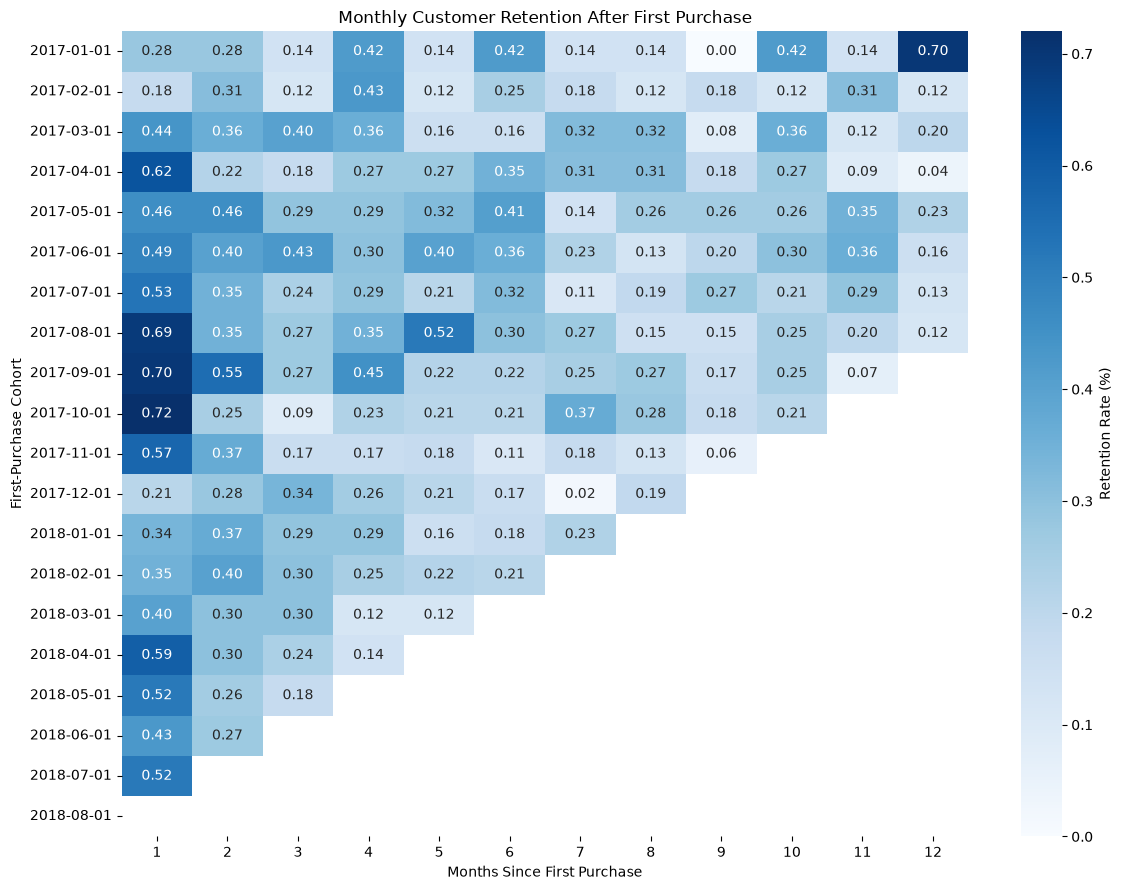

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
retention_matrix_post_purchase = retention_matrix.drop(columns=0)

plt.figure(figsize=(12, 9))

sns.heatmap(
    retention_matrix_post_purchase,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    mask=retention_matrix_post_purchase.isna(),
    cbar_kws={"label": "Retention Rate (%)"}
)

plt.title("Monthly Customer Retention After First Purchase")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First-Purchase Cohort")

plt.tight_layout()
plt.show()

### Customer Cohort Retention Insights

Monthly cohort analysis shows consistently low repeat-purchase activity after customers' first delivered orders.

- Month-1 retention remains below 1% across all observed cohorts.
- Retention in subsequent months is also generally below 1%, with no clear sustained improvement across newer customer cohorts.
- Some individual cohorts show isolated increases in later months, but these patterns are not persistent across cohorts.
- More recent cohorts have fewer observable retention periods because the dataset ends before longer-term customer behavior can be observed.

These results reinforce the earlier finding that repeat purchasing is limited. Customer acquisition appears to contribute substantially more to transaction volume than recurring purchases from existing customers.

Retention here represents the percentage of customers who purchase again in a specific month after their first purchase, rather than cumulative repeat-purchase behavior.

In [12]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/02_monthly_retention_summary.sql", "r") as file:
    retention_summary_query = file.read()

monthly_retention_summary = pd.read_sql_query(
    retention_summary_query,
    conn
)

conn.close()

monthly_retention_summary

,months_since_first_purchase,eligible_cohorts,eligible_customers,active_customers,weighted_retention_rate_pct
0,1,22,87214,421,0.48
1,2,21,81265,273,0.34
2,3,20,75387,192,0.25
3,4,19,68881,176,0.26
4,5,18,62299,140,0.22
5,6,17,55525,129,0.23
6,7,16,49237,102,0.21
7,8,15,42395,86,0.20
8,9,14,37057,60,0.16
9,10,13,29997,75,0.25


### Weighted Monthly Retention

Customer retention remains very low throughout the first year after initial purchase.

- Month-1 weighted retention is 0.48%, the highest rate within the observed 12-month period.
- Subsequent monthly retention rates generally remain between approximately 0.16% and 0.34%.
- This reinforces the earlier finding that repeat purchasing is limited and that most marketplace activity comes from customers who purchase only once.

The number of eligible customers decreases for longer retention windows because more recent cohorts have not yet had enough observation time. Therefore, later-month retention rates should not be interpreted as being calculated from the same customer population as earlier months.

In [15]:
conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/03_category_affinity.sql", "r") as file:
    affinity_query = file.read()

category_affinity = pd.read_sql_query(
    affinity_query,
    conn
)

conn.close()

print(category_affinity.shape)
category_affinity.head(15)

(18, 9)


,category_a,category_b,pair_orders,category_a_orders,category_b_orders,support_pct,confidence_a_to_b_pct,confidence_b_to_a_pct,lift
0,bed_bath_table,home_confort,43,9272,392,0.045,0.46,10.97,1.14
1,construction_tools_lights,furniture_decor,11,242,6307,0.011,4.55,0.17,0.70
2,furniture_decor,home_construction,13,6307,483,0.013,0.21,2.69,0.41
3,baby,cool_stuff,20,2809,3559,0.021,0.71,0.56,0.19
4,baby,toys,19,2809,3804,0.020,0.68,0.50,0.17
5,housewares,unknown,14,5743,1392,0.015,0.24,1.01,0.17
6,bed_bath_table,furniture_decor,70,9272,6307,0.073,0.75,1.11,0.12
7,furniture_decor,garden_tools,16,6307,3448,0.017,0.25,0.46,0.07
8,baby,furniture_decor,12,2809,6307,0.012,0.43,0.19,0.07
9,furniture_decor,housewares,24,6307,5743,0.025,0.38,0.42,0.06


### Category Affinity Metric Definitions

The category affinity table measures how often two product categories appear together in the same delivered order and whether that co-occurrence is stronger than expected based on each category's individual popularity.

- **category_a / category_b**: The two product categories being compared. The alphabetical ordering is used only to avoid duplicate pairs such as `baby + toys` and `toys + baby`.

- **pair_orders**: Number of delivered orders that contain at least one product from both categories.

- **category_a_orders**: Total number of delivered orders containing `category_a`.

- **category_b_orders**: Total number of delivered orders containing `category_b`.

- **support_pct**: Percentage of all delivered orders that contain both categories.

  `support = pair_orders / total delivered orders`

- **confidence_a_to_b_pct**: Among orders containing `category_a`, the percentage that also contain `category_b`.

  `confidence(A → B) = pair_orders / category_a_orders`

- **confidence_b_to_a_pct**: Among orders containing `category_b`, the percentage that also contain `category_a`.

  `confidence(B → A) = pair_orders / category_b_orders`

- **lift**: Measures whether the two categories are purchased together more or less often than expected if their purchases were independent.

  `lift(A, B) = confidence(A → B) / P(B)`

  Interpretation:
  - `lift > 1`: positive association; the categories co-occur more often than expected.
  - `lift = 1`: no meaningful association beyond their individual purchase frequencies.
  - `lift < 1`: the categories co-occur less often than expected.

Pair frequency and confidence should therefore be interpreted together with lift. A pair can have many shared orders simply because both categories are individually popular, without representing a strong cross-category purchasing relationship.

### Category Affinity Insights

Cross-category purchasing is relatively limited among delivered orders.

Although some category pairs appear together more frequently than others, pair frequency alone does not imply strong purchase affinity. Most of the high-frequency category pairs have lift values below 1, indicating that they co-occur less often than would be expected based on their individual purchase frequencies.

The `bed_bath_table` and `home_confort` pair stands out among the most frequent combinations, with 43 shared orders and a lift of 1.14, suggesting a modest positive association.

Overall, the results suggest that customer baskets are generally concentrated within individual product categories rather than containing strong cross-category combinations.

### Strongest Category Affinity Pairs

After ranking category pairs by lift, only one frequently observed pair shows a positive association:

- `bed_bath_table` + `home_confort`
- 43 shared delivered orders
- Lift: 1.14
- Confidence (`bed_bath_table` → `home_confort`): 0.46%
- Confidence (`home_confort` → `bed_bath_table`): 10.97%

The asymmetric confidence reflects the large difference in category size. `bed_bath_table` appears in 9,272 delivered orders, while `home_confort` appears in only 392.

Therefore, customers purchasing `home_confort` products appear relatively more likely to also purchase `bed_bath_table` products, suggesting a potential cross-sell relationship.

However, the association is modest and is based on only 43 shared orders, so it should be interpreted as a potential behavioral signal rather than a strong or causal relationship.

Most other frequently observed category pairs have lift values below 1, indicating limited cross-category affinity at the category level.

In [16]:
conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/04_basket_structure.sql", "r") as file:
    basket_query = file.read()

basket_structure = pd.read_sql_query(
    basket_query,
    conn
)

conn.close()

basket_structure

,category_count,orders,order_share_pct
0,1,95698,99.19
1,2,762,0.79
2,3,18,0.02


### Basket Structure Insights

Delivered orders are overwhelmingly concentrated within a single product category.

- 99.19% of delivered orders contain products from only one category.
- 0.79% contain products from two categories.
- Only 0.02% contain products from three categories.

Therefore, only about 0.81% of delivered orders contain multiple product categories.

This basket structure helps explain the weak category affinity observed in the market basket analysis. Because cross-category purchases are rare, most category pairs have low support and lift values below 1.

Rather than indicating a failure to identify meaningful product combinations, the results suggest that customers on the marketplace generally complete category-focused purchases instead of building broad multi-category baskets.

In [17]:
conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/05_seller_performance.sql", "r") as file:
    seller_query = file.read()

seller_performance = pd.read_sql_query(
    seller_query,
    conn
)

conn.close()

print(seller_performance.shape)
seller_performance.head(15)

(425, 8)


,seller_id,delivered_orders,gmv,items_sold,gmv_per_order,avg_review_score,late_delivery_rate_pct,gmv_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,1124,226987.93,1148,201.95,4.15,11.57,1
1,53243585a1d6dc2643021fd1853d8905,348,217940.44,400,626.27,4.19,4.31,2
2,4a3ca9315b744ce9f8e9374361493884,1772,196882.12,1949,111.11,3.85,11.00,3
3,fa1c13f2614d7b5c4749cbc52fecda94,578,190917.14,579,330.31,4.37,10.21,4
4,7c67e1448b00f6e969d365cea6b010ab,973,186570.05,1355,191.75,3.50,10.07,5
5,7e93a43ef30c4f03f38b393420bc753a,319,165981.49,322,520.32,4.36,5.64,6
6,da8622b14eb17ae2831f4ac5b9dab84a,1311,159816.87,1548,121.90,4.18,7.63,7
7,7a67c85e85bb2ce8582c35f2203ad736,1145,139658.69,1155,121.97,4.27,5.94,8
8,1025f0e2d44d7041d6cf58b6550e0bfa,910,138208.56,1420,151.88,4.01,10.11,9
9,955fee9216a65b617aa5c0531780ce60,1261,131836.71,1472,104.55,4.20,7.77,10


### Seller Performance Insights

Seller performance varies substantially even among the highest-GMV merchants.

Some top sellers generate GMV primarily through high order volume, while others achieve similar GMV with fewer but higher-value orders. Service quality also differs meaningfully across leading sellers.

For example:

- The #2 seller by GMV generates 217,940 BRL from only 348 delivered orders, with a GMV per order of 626.27 BRL. Its late-delivery rate is relatively low at 4.31%, while its average review score is 4.19.
- The #3 seller generates 196,882 BRL from 1,772 orders, indicating a much more volume-driven business model. However, its average review score is lower at 3.85 and its late-delivery rate is 11.00%.
- The #5 seller combines high GMV with an average review score of only 3.50 and a late-delivery rate of 10.07%, suggesting a potential service-quality risk despite strong commercial performance.

These results show that GMV alone does not fully capture seller performance. A more useful seller evaluation should consider both commercial contribution and customer-experience metrics.

In [18]:
conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/06_seller_risk_segments.sql", "r") as file:
    seller_risk_query = file.read()

seller_risk_segments = pd.read_sql_query(
    seller_risk_query,
    conn
)

conn.close()

seller_risk_segments["seller_segment"].value_counts()

seller_segment
Standard Seller                 318
High-Value Mixed Performance     57
Priority Monitoring              43
High-Value Strong Performer       7
Name: count, dtype: int64

In [19]:
seller_risk_segments[
    seller_risk_segments["seller_segment"] == "Priority Monitoring"
].head(15)

,seller_id,delivered_orders,gmv,avg_review_score,late_delivery_rate_pct,gmv_quartile,review_risk_quartile,late_risk_quartile,seller_segment
0,4869f7a5dfa277a7dca6462dcf3b52b2,1124,226987.93,4.15,11.57,1,2,1,Priority Monitoring
1,4a3ca9315b744ce9f8e9374361493884,1772,196882.12,3.85,11.00,1,1,1,Priority Monitoring
2,7c67e1448b00f6e969d365cea6b010ab,973,186570.05,3.50,10.07,1,1,2,Priority Monitoring
3,6560211a19b47992c3666cc44a7e94c0,1819,120702.83,3.98,6.43,1,1,3,Priority Monitoring
4,7d13fca15225358621be4086e1eb0964,558,112436.18,4.04,12.19,1,2,1,Priority Monitoring
5,1f50f920176fa81dab994f9023523100,1399,106655.71,4.14,10.58,1,2,1,Priority Monitoring
6,f7ba60f8c3f99e7ee4042fdef03b70c4,218,68070.00,4.22,15.60,1,3,1,Priority Monitoring
7,cca3071e3e9bb7d12640c9fbe2301306,699,63035.16,3.88,5.87,1,1,3,Priority Monitoring
8,04308b1ee57b6625f47df1d56f00eedf,92,58991.80,3.95,11.96,1,1,1,Priority Monitoring
9,522620dcb18a6b31cd7bdf73665113a9,172,56690.49,3.91,10.47,1,1,1,Priority Monitoring


### Seller Risk Segmentation

To evaluate sellers beyond GMV alone, sellers with at least 50 delivered orders were segmented using three performance dimensions:

- commercial contribution, measured by GMV;
- customer satisfaction, measured by average review score;
- delivery performance, measured by the seller-associated late-delivery rate.

A total of **425 sellers** met the minimum-volume requirement and were included in the segmentation.

#### Quartile Definitions

Each performance metric was divided into four approximately equal groups using SQL `NTILE(4)`.

**GMV Quartile**

Sellers are ranked from highest to lowest GMV:

- `gmv_quartile = 1`: highest-GMV approximately 25% of sellers
- `gmv_quartile = 2`: second-highest GMV group
- `gmv_quartile = 3`: third GMV group
- `gmv_quartile = 4`: lowest-GMV approximately 25%

Therefore, `gmv_quartile = 1` represents the platform's **high-value sellers**.

**Review Risk Quartile**

Sellers are ranked from lowest to highest average review score:

- `review_risk_quartile = 1`: lowest-review approximately 25% of sellers, representing the highest review-related risk
- `review_risk_quartile = 2`: second-highest review-risk group
- `review_risk_quartile = 3`: lower-risk group
- `review_risk_quartile = 4`: highest-review approximately 25%, representing the strongest customer satisfaction

Therefore, a **lower review-risk quartile number means higher risk**.

**Late-Delivery Risk Quartile**

Sellers are ranked from highest to lowest seller-associated late-delivery rate:

- `late_risk_quartile = 1`: highest late-delivery approximately 25% of sellers, representing the greatest delivery risk
- `late_risk_quartile = 2`: second-highest delivery-risk group
- `late_risk_quartile = 3`: lower-risk group
- `late_risk_quartile = 4`: lowest late-delivery approximately 25%, representing the strongest delivery performance

Therefore, a **lower late-risk quartile number also means higher risk**.

Because 425 sellers cannot be divided perfectly into four equal groups, quartile sizes may differ slightly.

#### Seller Segment Definitions

Based on these three quartiles, sellers are classified into four business segments.

**Priority Monitoring**

A seller is classified as `Priority Monitoring` when:

`gmv_quartile = 1`

and at least one of the following conditions is true:

`review_risk_quartile = 1`

or

`late_risk_quartile = 1`

These sellers are among the highest-GMV sellers but are also in the highest-risk quartile for customer reviews, late delivery, or both. They are prioritized because service-quality problems among high-value sellers may affect a relatively large amount of marketplace activity.

**High-Value Strong Performer**

A seller is classified as `High-Value Strong Performer` when:

- `gmv_quartile = 1`
- `review_risk_quartile = 4`
- `late_risk_quartile = 4`

These sellers combine high commercial contribution with both strong customer reviews and relatively low late-delivery rates.

**High-Value Mixed Performance**

These sellers belong to the highest GMV quartile but do not meet the criteria for either `Priority Monitoring` or `High-Value Strong Performer`.

Their service performance is therefore neither among the highest-risk nor consistently among the strongest across both customer-experience dimensions.

**Standard Seller**

All sellers outside the highest GMV quartile are classified as `Standard Seller` in this prioritization framework.

This label does not imply poor performance; it simply indicates that these sellers are not part of the high-GMV group targeted by this particular risk-monitoring framework.

### Segmentation Results

Among the 425 eligible sellers:

- **43 sellers** are classified as `Priority Monitoring`.
- **7 sellers** are classified as `High-Value Strong Performer`.
- **57 sellers** are classified as `High-Value Mixed Performance`.
- **318 sellers** are classified as `Standard Seller`.

There are 107 sellers in the highest GMV quartile. Of these, approximately **40% (43 sellers)** fall into the Priority Monitoring group, indicating that a meaningful share of commercially important sellers also show elevated customer-experience or delivery risk.

Several of the highest-GMV sellers illustrate this tradeoff. For example, the #3 seller by GMV has an average review score of 3.85 and a seller-associated late-delivery rate of 11.00%, placing it in the highest-risk quartile for both review performance and late delivery.

The segmentation therefore provides a more actionable seller-management framework than GMV ranking alone. Rather than treating all high-GMV sellers equally, the marketplace can distinguish between strong performers and high-value sellers that may warrant additional service-quality monitoring.

> Note: late-delivery rate is based on the final delivery outcome of orders associated with each seller. Because an order may contain items from multiple sellers, this metric should be interpreted as a **seller-associated delivery outcome**, not as proof that a particular seller caused the delivery delay.

In [20]:
conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/07_payment_reconciliation.sql", "r") as file:
    reconciliation_query = file.read()

payment_anomalies = pd.read_sql_query(
    reconciliation_query,
    conn
)

conn.close()

print("Number of flagged orders:", len(payment_anomalies))

payment_anomalies.head(15)

Number of flagged orders: 247


,anomaly_rank,order_id,gmv,freight,expected_order_value,payment_total,payment_difference,payment_records,reconciliation_status
0,1,ce6d150fb29ada17d2082f4847107665,1299.00,104.66,1403.66,1586.47,182.81,1.0,Payment Above Order Value
1,2,6e5fe7366a2e1bfbf3257dba0af1267f,179.19,108.72,287.91,406.92,119.01,1.0,Payment Above Order Value
2,3,70b742795bc441e94a44a084b6d9ce7a,269.99,196.94,466.93,578.82,111.89,1.0,Payment Above Order Value
3,4,996c7e73600ad3723e8627ab7bef81e4,559.90,28.00,587.90,664.43,76.53,1.0,Payment Above Order Value
4,5,70b7e94ea46d3e8b5bc12a50186edaf0,167.88,45.27,213.15,274.84,61.69,1.0,Payment Above Order Value
5,6,bc2c82b0ef78d2252b6176d1972db7c9,165.00,77.01,242.01,303.02,61.01,1.0,Payment Above Order Value
6,7,af9ffff2ce6b3defd34fd4c78857a379,395.65,17.52,413.17,466.97,53.80,1.0,Payment Above Order Value
7,8,262118ce178bb3e4590a3adcf6d62e6b,119.80,57.94,177.74,126.12,-51.62,1.0,Payment Below Order Value
8,9,bfdb5bbb06458d600a33d61f5f287472,297.00,51.93,348.93,394.36,45.43,1.0,Payment Above Order Value
9,10,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,209.80,44.65,254.45,293.89,39.44,1.0,Payment Above Order Value


In [21]:
payment_anomalies["reconciliation_status"].value_counts()

reconciliation_status
Payment Above Order Value    229
Payment Below Order Value     17
Missing Payment                1
Name: count, dtype: int64

In [22]:
conn = sqlite3.connect("../data/processed/olist_analytics.db")

with open("../sql/08_payment_reconciliation_summary.sql", "r") as file:
    reconciliation_summary_query = file.read()

payment_reconciliation_summary = pd.read_sql_query(
    reconciliation_summary_query,
    conn
)

conn.close()

payment_reconciliation_summary

,reconciliation_status,orders,order_share_pct,avg_absolute_difference,max_absolute_difference
0,Matched,96178,99.689,0.00,0.01
1,Payment Above Order Value,229,0.237,13.22,182.81
2,Minor Difference,53,0.055,0.11,1.00
3,Payment Below Order Value,17,0.018,11.62,51.62
4,Missing Payment,1,0.001,NaN,NaN


### Payment Reconciliation Insights

Customer payments were reconciled against the expected order value for each delivered order:

`Expected Order Value = GMV + Freight`

The following analytical monitoring rules were used:

- **Matched:** absolute difference ≤ 0.01 BRL
- **Minor Difference:** absolute difference > 0.01 BRL and ≤ 1.00 BRL
- **Payment Above Order Value:** payment exceeds expected order value by more than 1.00 BRL
- **Payment Below Order Value:** payment is lower than expected order value by more than 1.00 BRL
- **Missing Payment:** no payment record exists for the delivered order

These thresholds are project-specific monitoring rules rather than accounting standards.

### Reconciliation Results

Payment records are highly consistent with item and freight totals:

- **96,178 orders (99.689%)** are fully matched within 0.01 BRL.
- **53 orders (0.055%)** show only minor differences of no more than 1 BRL.
- **229 orders (0.237%)** have payment values more than 1 BRL above expected order value.
- **17 orders (0.018%)** have payment values more than 1 BRL below expected order value.
- **1 delivered order (0.001%)** has no payment record.

Overall, **99.744% of delivered orders have a payment difference of 1 BRL or less**, while only approximately **0.256%** are materially flagged under the monitoring rule.

Among materially mismatched orders, payments above expected order value have an average absolute difference of **13.22 BRL**, with a maximum of **182.81 BRL**. Payments below expected order value have an average absolute difference of **11.62 BRL**, with a maximum of **51.62 BRL**.

The results therefore suggest strong overall financial consistency between recorded customer payments and item-level order values, with a small number of transactions requiring further investigation.

The available dataset does not provide enough information to determine the underlying cause of these discrepancies, so the flagged transactions should be interpreted as **reconciliation anomalies rather than confirmed billing errors**.